In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install segmentation_models_pytorch h5py

import os, glob, re, random, time, json
import numpy as np, pandas as pd, h5py, torch
import torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = '/content/drive/MyDrive/TerraSeg/phase2'
os.makedirs(OUT, exist_ok=True)
print(device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda


In [ ]:
from huggingface_hub import snapshot_download
snapshot_download(repo_id="ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                  allow_patterns=["*train*"], local_dir="/content/l4s", max_workers=8)

for root, dirs, files in os.walk('/content/l4s'):
    if files: print(root, len(files), files[:2])

f = sorted(glob.glob('/content/l4s/**/image_*.h5', recursive=True))[0]
with h5py.File(f) as h:
    for k in h.keys(): print(f, k, h[k].shape, h[k].dtype)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7603 files:   0%|          | 0/7603 [00:00<?, ?it/s]

/content/l4s/annotations/train 3804 ['mask_413.h5', 'mask_2541.h5']
/content/l4s/.cache/huggingface 2 ['.gitignore', 'CACHEDIR.TAG']
/content/l4s/.cache/huggingface/download/annotations/train 7608 ['mask_2640.h5.metadata', 'mask_3343.h5.lock']
/content/l4s/.cache/huggingface/download/images/train 7598 ['image_232.h5.metadata', 'image_1528.h5.metadata']
/content/l4s/.cache/huggingface/trees 1 ['4b291891badf301b5c75c2153f0f8fe00eeb1435.json']
/content/l4s/images/train 3799 ['image_1311.h5', 'image_2149.h5']


In [ ]:
def num(p): return int(re.findall(r'(\d+)\.h5$', p)[0])

img_files  = sorted(glob.glob('/content/l4s/images/train/image_*.h5'), key=num)
mask_files = sorted(glob.glob('/content/l4s/annotations/train/mask_*.h5'), key=num)

# show the strays so you know what was ignored
stray = [p for p in glob.glob('/content/l4s/annotations/train/*') if not os.path.basename(p).startswith('mask_')]
print("Ignored stray files in annotations/train:", [os.path.basename(p) for p in stray])

print(len(img_files), len(mask_files))
assert len(img_files) == len(mask_files) > 0, (len(img_files), len(mask_files))
assert all(num(a) == num(b) for a, b in zip(img_files, mask_files)), "image/mask mismatch"

def first(h): return h[list(h.keys())[0]][:]
X = np.zeros((len(img_files), 14, 128, 128), dtype=np.float32)
Y = np.zeros((len(img_files), 1, 128, 128), dtype=np.float32)
for i, (a, b) in enumerate(zip(img_files, mask_files)):
    with h5py.File(a) as h: X[i] = np.nan_to_num(first(h)).transpose(2, 0, 1)
    with h5py.File(b) as h: Y[i, 0] = first(h)
print(X.shape, Y.shape, "landslide pixel share:", Y.mean().round(4))

# the stats print from the original Cell 3 (check the ranges look sensible)
for c in [0, 1, 2, 3, 12, 13]:
    print(f"ch{c}: min {X[:,c].min():.1f} max {X[:,c].max():.1f} mean {X[:,c].mean():.1f}")

Ignored stray files in annotations/train: ['image_1001.h5', 'image_10.h5', 'image_1.h5', 'image_100.h5', 'image_1000.h5']
3799 3799
(3799, 14, 128, 128) (3799, 1, 128, 128) landslide pixel share: 0.0232
ch0: min 0.0 max 3.1 mean 0.9
ch1: min 0.0 max 19.8 mean 0.9
ch2: min 0.0 max 31.6 mean 1.0
ch3: min 0.0 max 33.2 mean 1.0
ch12: min 0.0 max 4.0 mean 1.3
ch13: min 0.0 max 5.1 mean 1.6


In [ ]:
# Sentinel-2 bands sit in channels 0-11, slope in 12, DEM in 13.
# RGB = B4,B3,B2 = indices 3,2,1  (verify against the dataset description on Zenodo)
CHANNEL_SETS = {
    'A_RGB':          [3, 2, 1],
    'B_Optical12':    list(range(12)),
    'C_Optical+DEM':  list(range(14)),
}

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(X))
n_train = int(0.8 * len(X))
train_idx, val_idx = perm[:n_train], perm[n_train:]

# statistics from TRAIN ONLY, otherwise validation information leaks in
mean = X[train_idx].mean(axis=(0, 2, 3), keepdims=True)
std  = X[train_idx].std(axis=(0, 2, 3), keepdims=True) + 1e-6
Xn = (X - mean) / std

class PatchDS(Dataset):
    def __init__(self, idx, chans, augment=False):
        self.idx, self.chans, self.augment = idx, chans, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        x = torch.from_numpy(Xn[self.idx[i]][self.chans])
        y = torch.from_numpy(Y[self.idx[i]])
        if self.augment:
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        return x, y

def loaders(chans):
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(PatchDS(train_idx, chans, True),  batch_size=16, shuffle=True, generator=g)
    va = DataLoader(PatchDS(val_idx,   chans, False), batch_size=16, shuffle=False)
    return tr, va
print(len(train_idx), "train /", len(val_idx), "val")

3039 train / 760 val


In [ ]:
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, t):
        p = torch.sigmoid(logits).view(-1); tf = t.view(-1)
        dice = 1 - (2*(p*tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)
        return self.bce(logits, t) + dice

@torch.no_grad()
def evaluate(model, loader, thr=0.5):
    model.eval(); tp = fp = fn = tn = 0; loss_sum = 0; crit = BCEDiceLoss()
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x); loss_sum += crit(out, y).item()
        p = (torch.sigmoid(out) > thr).float()
        tp += (p*y).sum().item(); fp += (p*(1-y)).sum().item()
        fn += ((1-p)*y).sum().item(); tn += ((1-p)*(1-y)).sum().item()
    eps = 1e-9
    prec, rec = tp/(tp+fp+eps), tp/(tp+fn+eps)
    return dict(Precision=prec, Recall=rec, F1=2*prec*rec/(prec+rec+eps),
                IoU=tp/(tp+fp+fn+eps), PixelAcc=(tp+tn)/(tp+tn+fp+fn+eps),
                val_loss=loss_sum/len(loader))

In [ ]:
def build(in_ch):
    # imagenet weights work with any in_ch: smp adapts the first conv layer
    return smp.Unet('resnet34', encoder_weights='imagenet', in_channels=in_ch, classes=1).to(device)

def train(name, chans, epochs=40, patience=8, lr=5e-4):
    set_seed()
    tr, va = loaders(chans)
    model = build(len(chans)); crit = BCEDiceLoss()
    opt = optim.Adam(model.parameters(), lr=lr)
    ckpt = f'{OUT}/{name}.pth'; best, bad = 1e9, 0
    for ep in range(epochs):
        model.train(); run = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        m = evaluate(model, va)
        print(f"{name} ep{ep+1:02d} train {run/len(tr):.4f} val {m['val_loss']:.4f} IoU {m['IoU']:.3f}")
        if m['val_loss'] < best: best, bad = m['val_loss'], 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience: print("early stop"); break
    model.load_state_dict(torch.load(ckpt))
    return model, evaluate(model, va)

In [ ]:
results, models = {}, {}
for name, chans in CHANNEL_SETS.items():
    if os.path.exists(f'{OUT}/{name}.pth'):          # reuse after a Colab disconnect
        m = build(len(chans)); m.load_state_dict(torch.load(f'{OUT}/{name}.pth'))
        _, va = loaders(chans); results[name] = evaluate(m, va); models[name] = m
    else:
        models[name], results[name] = train(name, chans)

df = pd.DataFrame(results).T.round(3)
df.to_csv(f'{OUT}/phase2a_results.csv'); df

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

A_RGB ep01 train 0.9968 val 0.7150 IoU 0.328
A_RGB ep02 train 0.5821 val 0.5577 IoU 0.381
A_RGB ep03 train 0.5299 val 0.4619 IoU 0.470
A_RGB ep04 train 0.4904 val 0.4518 IoU 0.478
A_RGB ep05 train 0.4522 val 0.4074 IoU 0.516
A_RGB ep06 train 0.4766 val 0.4267 IoU 0.498
A_RGB ep07 train 0.4443 val 0.4172 IoU 0.510
A_RGB ep08 train 0.4396 val 0.3903 IoU 0.531
A_RGB ep09 train 0.4304 val 0.4218 IoU 0.503
A_RGB ep10 train 0.4120 val 0.3930 IoU 0.532
A_RGB ep11 train 0.4222 val 0.3827 IoU 0.537
A_RGB ep12 train 0.4135 val 0.3732 IoU 0.547
A_RGB ep13 train 0.4127 val 0.4171 IoU 0.510
A_RGB ep14 train 0.4085 val 0.3655 IoU 0.556
A_RGB ep15 train 0.4028 val 0.3960 IoU 0.522
A_RGB ep16 train 0.3938 val 0.3775 IoU 0.542
A_RGB ep17 train 0.3875 val 0.3679 IoU 0.553
A_RGB ep18 train 0.3859 val 0.3701 IoU 0.553
A_RGB ep19 train 0.4011 val 0.3783 IoU 0.543
A_RGB ep20 train 0.3963 val 0.4311 IoU 0.481
A_RGB ep21 train 0.3844 val 0.3556 IoU 0.565
A_RGB ep22 train 0.3716 val 0.3702 IoU 0.550
A_RGB ep23

,Precision,Recall,F1,IoU,PixelAcc,val_loss
A_RGB,0.725,0.732,0.729,0.573,0.988,0.347
B_Optical12,0.722,0.703,0.712,0.553,0.987,0.362
C_Optical+DEM,0.754,0.778,0.766,0.621,0.989,0.296


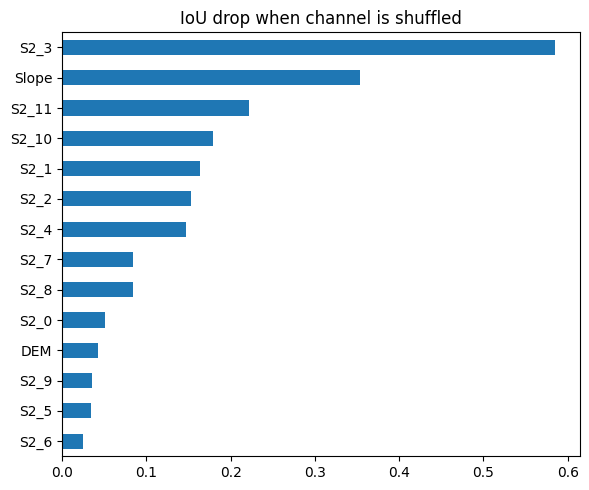

In [ ]:
# Permutation importance for run C: shuffle ONE channel across patches and see how much IoU drops.
chans = CHANNEL_SETS['C_Optical+DEM']; model = models['C_Optical+DEM']
_, va = loaders(chans)
base = evaluate(model, va)['IoU']; drops = {}
names = [f'S2_{i}' for i in range(12)] + ['Slope', 'DEM']
for j, nm in enumerate(names):
    saved = Xn[val_idx, j].copy()
    Xn[val_idx, j] = Xn[np.random.permutation(val_idx), j]
    drops[nm] = base - evaluate(model, va)['IoU']
    Xn[val_idx, j] = saved
pd.Series(drops).sort_values().plot.barh(figsize=(6, 5), title='IoU drop when channel is shuffled')
plt.tight_layout(); plt.savefig(f'{OUT}/channel_importance.png', dpi=150); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install xarray netcdf4 h5netcdf huggingface_hub segmentation_models_pytorch
import os, re, glob, ast, random, json, shutil, collections
import numpy as np, pandas as pd, xarray as xr, torch
import torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

SEED = 42
SEEDS = [42]            # add 123, 777 for the final two experiments if time allows
OUT = '/content/drive/MyDrive/TerraSeg/phase2b_fix'; os.makedirs(OUT, exist_ok=True)
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(userdata.get('HF_TOKEN'))      # optional free token
except Exception:
    print("No HF_TOKEN, continuing anonymously")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 98.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 75.4 MB/s eta 0:00:00
cuda
No HF_TOKEN, continuing anonymously


In [ ]:
NC_RE = re.compile(r'^(.*)_(s1asc|s1dsc|s2)_(\d+)\.nc$')
def find_pairs(root):
    d = collections.defaultdict(dict)
    for p in glob.glob(f'{root}/**/*.nc', recursive=True):
        m = NC_RE.match(os.path.basename(p))
        if m and m.group(2) in ('s2', 's1asc'): d[(m.group(1), m.group(3))][m.group(2)] = p
    return {k: v for k, v in d.items() if len(v) == 2}

def attr_dict(v): return v if isinstance(v, dict) else ast.literal_eval(str(v))
_ann = {}
def is_annotated(path):
    if path not in _ann:
        with xr.open_dataset(path) as ds: _ann[path] = str(ds.attrs.get('annotated')).lower() == 'true'
    return _ann[path]

CLOUD = [3, 8, 9, 10]      # SCL classes: cloud shadow, medium/high cloud, thin cirrus
def first_clear(cf, start, step, limit=0.2):
    rng = range(start, len(cf)) if step > 0 else range(start, -1, -1)
    return next((t for t in rng if cf[t] < limit), start)
def fix2d(a, S=128):
    out = np.zeros((a.shape[0], S, S), np.float32); h, w = min(S, a.shape[1]), min(S, a.shape[2])
    out[:, :h, :w] = a[:, :h, :w]; return out

def load_pair(p_s2, p_s1, S=128):
    with xr.open_dataset(p_s2) as s2, xr.open_dataset(p_s1) as s1:
        mask = (s2['MASK'].values.max(axis=0) > 0).astype(np.float32)     # max over time, not median
        if mask.sum() == 0: return None
        a2, a1 = attr_dict(s2.attrs['pre_post_dates']), attr_dict(s1.attrs['pre_post_dates'])
        scl = s2['SCL'].values
        cf = np.array([np.isin(scl[t], CLOUD).mean() for t in range(scl.shape[0])])
        post2, pre2 = first_clear(cf, a2['post'], +1), first_clear(cf, a2['pre'], -1)
        bands = sorted(v for v in s2.data_vars if v.startswith('B'))
        S2 = np.nan_to_num(np.stack([s2[b].values.astype(np.float32) for b in bands], 1))
        sar = [v for v in ('VV', 'VH') if v in s1.data_vars]
        S1 = np.nan_to_num(np.stack([s1[b].values.astype(np.float32) for b in sar], 1), nan=-25.0)
        dem = np.nan_to_num(s2['DEM'].values.astype(np.float32)).mean(axis=0, keepdims=True)
        g = {'S2': S2[post2], 'S2d': S2[post2] - S2[pre2],
             'S1': S1[a1['post']], 'S1d': S1[a1['post']] - S1[a1['pre']], 'DEM': dem}
        return {k: fix2d(v, S) for k, v in g.items()}, fix2d(mask[None], S)

def split_by_region(keys, seed=42, frac=0.15):
    regions = np.array([k[0] for k in keys]); ureg = sorted(set(regions)); random.Random(seed).shuffle(ureg)
    n, val, test, cv, ct = len(keys), [], [], 0, 0
    for r in ureg:
        c = (regions == r).sum()
        if cv < frac * n: val.append(r); cv += c
        elif ct < frac * n: test.append(r); ct += c
    tr = np.where(~np.isin(regions, val + test))[0]
    return tr, np.where(np.isin(regions, val))[0], np.where(np.isin(regions, test))[0]
print("loader ready")

loader ready


In [ ]:
from huggingface_hub import HfApi, snapshot_download
REPO = 'paulhoehn/Sen12Landslides'; N_PATCHES = 1000; MAX_PARTS = 8; MIN_FREE_GB = 15
info = HfApi().dataset_info(REPO, files_metadata=True)
parts = {s: sorted((x.rfilename, x.size or 0) for x in info.siblings
                   if x.rfilename.startswith(f'data_harmonized/{s}/') and x.rfilename.endswith('.tar.gz'))
         for s in ('s2', 's1asc')}
for s, v in parts.items(): print(s, len(v), 'parts; first part', round(v[0][1]/1e9, 2) if v else None, 'GB')

def good_pairs():
    return [k for k, v in sorted(find_pairs('/content/s12l').items()) if is_annotated(v['s2'])]

for i in range(MAX_PARTS):
    if len(good_pairs()) >= N_PATCHES: break
    if shutil.disk_usage('/content').free / 1e9 < MIN_FREE_GB: print("low disk, stopping"); break
    for s in ('s2', 's1asc'):
        if i >= len(parts[s]): continue
        n = parts[s][i][0]
        snapshot_download(REPO, repo_type='dataset', allow_patterns=[n], local_dir='/content/s12l_dl', max_workers=8)
        shutil.unpack_archive(f'/content/s12l_dl/{n}', '/content/s12l'); os.remove(f'/content/s12l_dl/{n}')
    print('after part', i + 1, ':', len(good_pairs()), 'annotated S2+S1 pairs')

s2 28 parts; first part 1.47 GB
s1asc 14 parts; first part 1.49 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

after part 1 : 260 annotated S2+S1 pairs


... (21 outputs left out)

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

after part 6 : 1178 annotated S2+S1 pairs


In [ ]:
pairs = find_pairs('/content/s12l'); keys = good_pairs(); random.Random(SEED).shuffle(keys)
G, M, K, errs = collections.defaultdict(list), [], [], 0
for k in keys:
    try: r = load_pair(pairs[k]['s2'], pairs[k]['s1asc'])
    except Exception as e:
        errs += 1
        if errs <= 3: print("load error:", k, repr(e)[:200])
        continue
    if r is None: continue
    g, m = r
    for name, a in g.items(): G[name].append(a)
    M.append(m); K.append(k)
    if len(K) >= N_PATCHES: break
assert len(K) > 50, f"only {len(K)} patches loaded ({errs} errors) - send me the output"
order = ['S2', 'S2d', 'S1', 'S1d', 'DEM']
arrs = {n: np.stack(G[n]) for n in order}
CH, off = {}, 0
for n in order: CH[n] = list(range(off, off + arrs[n].shape[1])); off += arrs[n].shape[1]
X = np.concatenate([arrs[n] for n in order], axis=1); M = np.stack(M); del G, arrs
print(X.shape, "| landslide pixel share:", round(float(M.mean()) * 100, 2), "% | load errors:", errs)
print({n: len(v) for n, v in CH.items()})

load error: ('china', '830') TypeError('tuple indices must be integers or slices, not str')
load error: ('china', '865') TypeError('tuple indices must be integers or slices, not str')
load error: ('china', '864') TypeError('tuple indices must be integers or slices, not str')
(1000, 25, 128, 128) | landslide pixel share: 2.48 % | load errors: 17
{'S2': 10, 'S2d': 10, 'S1': 2, 'S1d': 2, 'DEM': 1}


In [ ]:
tr, va, te = split_by_region(K)
assert min(len(tr), len(va), len(te)) > 0, "empty split - too few regions; send me the output"
print(len(tr), "train /", len(va), "val /", len(te), "test patches")
for nm, ix in (('train', tr), ('val', va), ('test', te)):
    print(nm, "landslide share", round(float(M[ix].mean()) * 100, 2), "% | regions:", sorted({K[i][0] for i in ix})[:8])
mean = X[tr].mean(axis=(0, 2, 3)); std = X[tr].std(axis=(0, 2, 3)) + 1e-6
X -= mean.reshape(1, -1, 1, 1); X /= std.reshape(1, -1, 1, 1)          # train-only statistics, in place

OPT = CH['S2'] + CH['S2d']
EXPS = {
    'S2+DEM':                 dict(ch=CH['S2'] + CH['DEM']),
    'S1+DEM':                 dict(ch=CH['S1'] + CH['DEM']),
    'S1+S2+DEM':              dict(ch=CH['S1'] + CH['S2'] + CH['DEM']),
    'S1+S2+DEM+change':       dict(ch=CH['S1'] + CH['S1d'] + CH['S2'] + CH['S2d'] + CH['DEM']),
    'fused+change+opt.dropout': dict(ch=CH['S1'] + CH['S1d'] + CH['S2'] + CH['S2d'] + CH['DEM'], drop=0.5),
}

365 train / 352 val / 283 test patches
train landslide share 2.31 % | regions: ['chimanimani']
val landslide share 3.22 % | regions: ['dominicamaria']
test landslide share 1.77 % | regions: ['china', 'hiroshima']


In [ ]:
class DS(Dataset):
    def __init__(self, idx, ch, aug=False, drop=0.0, blank=False):
        self.idx, self.ch, self.aug, self.drop, self.blank = idx, ch, aug, drop, blank
        self.opt_pos = [i for i, c in enumerate(ch) if c in OPT]
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(X[j][self.ch]); y = torch.from_numpy(M[j].copy())
        if self.aug:
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        if self.opt_pos and (self.blank or (self.drop and random.random() < self.drop)):
            x[self.opt_pos] = 0                       # 0 = channel mean after normalisation ("cloudy day")
        return x, y

class BCEDiceLoss(nn.Module):
    def forward(self, lg, t):
        p, tf = torch.sigmoid(lg).view(-1), t.view(-1)
        return F.binary_cross_entropy_with_logits(lg, t) + 1 - (2 * (p * tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)

@torch.no_grad()
def evaluate(model, ldr):
    model.eval(); tp = fp = fn = 0.0
    for x, y in ldr:
        x, y = x.to(device), y.to(device); p = (torch.sigmoid(model(x)) > 0.5).float()
        tp += (p * y).sum().item(); fp += (p * (1 - y)).sum().item(); fn += ((1 - p) * y).sum().item()
    e = 1e-9; pr, rc = tp / (tp + fp + e), tp / (tp + fn + e)
    return dict(IoU=tp / (tp + fp + fn + e), F1=2 * pr * rc / (pr + rc + e), Precision=pr, Recall=rc)

def run_exp(name, cfg, seed, epochs=40, patience=10):
    tag = re.sub(r'[^A-Za-z0-9]+', '_', name) + f'_s{seed}'
    rp, cp = f'{OUT}/{tag}.json', f'{OUT}/{tag}.pth'
    if os.path.exists(rp): print("skip", tag); return json.load(open(rp))
    ch = cfg['ch']; set_seed(seed); g = torch.Generator().manual_seed(seed)
    tr_l = DataLoader(DS(tr, ch, True, cfg.get('drop', 0.0)), batch_size=16, shuffle=True, generator=g)
    va_l = DataLoader(DS(va, ch), batch_size=32)
    te_l = DataLoader(DS(te, ch), batch_size=32); te_c = DataLoader(DS(te, ch, blank=True), batch_size=32)
    model = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=len(ch), classes=1).to(device)
    crit, opt = BCEDiceLoss(), optim.Adam(model.parameters(), lr=5e-4); best, bad = -1.0, 0
    for ep in range(epochs):
        model.train(); run = 0.0
        for x, y in tr_l:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        v = evaluate(model, va_l)
        print(f"[{tag}] ep {ep+1:02d} train {run/len(tr_l):.4f} | val IoU {v['IoU']:.4f}")
        if v['IoU'] > best: best, bad = v['IoU'], 0; torch.save(model.state_dict(), cp)
        else:
            bad += 1
            if bad >= patience: print("early stop"); break
    model.load_state_dict(torch.load(cp))
    res = {'exp': name, 'seed': seed, 'val': evaluate(model, va_l), 'test': evaluate(model, te_l), 'test_cloudy': evaluate(model, te_c)}
    json.dump(res, open(rp, 'w')); del model, opt; torch.cuda.empty_cache(); return res

In [ ]:
rows = []
for name, cfg in EXPS.items():
    for seed in SEEDS:
        r = run_exp(name, cfg, seed)
        rows.append({'exp': name, **{f'{k}': v for k, v in r['test'].items()},
                     'IoU_cloudy': r['test_cloudy']['IoU'], 'F1_cloudy': r['test_cloudy']['F1'], 'val_IoU': r['val']['IoU']})
df = pd.DataFrame(rows).groupby('exp', sort=False).mean(numeric_only=True).round(3)
df.to_csv(f'{OUT}/phase2b_fixed_results.csv'); df

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[S2_DEM_s42] ep 01 train 1.5761 | val IoU 0.0124
[S2_DEM_s42] ep 02 train 1.2780 | val IoU 0.0115
[S2_DEM_s42] ep 03 train 1.1601 | val IoU 0.0236
[S2_DEM_s42] ep 04 train 1.0731 | val IoU 0.0014
[S2_DEM_s42] ep 05 train 0.9953 | val IoU 0.0004
[S2_DEM_s42] ep 06 train 0.9240 | val IoU 0.0002
[S2_DEM_s42] ep 07 train 0.8460 | val IoU 0.0008
[S2_DEM_s42] ep 08 train 0.7904 | val IoU 0.0010
[S2_DEM_s42] ep 09 train 0.7404 | val IoU 0.0004
[S2_DEM_s42] ep 10 train 0.7043 | val IoU 0.0030
[S2_DEM_s42] ep 11 train 0.6661 | val IoU 0.0020
[S2_DEM_s42] ep 12 train 0.6517 | val IoU 0.0053
[S2_DEM_s42] ep 13 train 0.6296 | val IoU 0.0014
early stop
[S1_DEM_s42] ep 01 train 1.5785 | val IoU 0.0318
[S1_DEM_s42] ep 02 train 1.2954 | val IoU 0.0002
[S1_DEM_s42] ep 03 train 1.1985 | val IoU 0.0260
[S1_DEM_s42] ep 04 train 1.1319 | val IoU 0.0075
[S1_DEM_s42] ep 05 train 1.0964 | val IoU 0.0001
[S1_DEM_s42] ep 06 train 1.0702 | val IoU 0.0001
[S1_DEM_s42] ep 07 train 1.0498 | val IoU 0.0035
[S1_DEM_s

,IoU,F1,Precision,Recall,IoU_cloudy,F1_cloudy,val_IoU
exp,,,,,,,
S2+DEM,0.017,0.034,0.022,0.070,0.012,0.025,0.024
S1+DEM,0.018,0.035,0.018,0.761,0.018,0.035,0.032
S1+S2+DEM,0.076,0.140,0.575,0.080,0.000,0.000,0.040
S1+S2+DEM+change,0.063,0.118,0.103,0.138,0.000,0.000,0.057
fused+change+opt.dropout,0.010,0.020,0.020,0.020,0.000,0.000,0.041
